# Tâche 4 — Analyse des tendances par année de sortie

**Programme :** Auspify — Data Analysis Using Python (Internship)
**Niveau :** Moyen
**Objectif :** analyser comment la production de contenus Netflix a évolué au fil des années.

> ⚠️ Point méthodologique : on distingue **`release_year`** (année de production/sortie du contenu) de **`added_year`** (année où Netflix l'a mis en ligne). Cette tâche porte sur la **production** (`release_year`).

## Plan de travail (Task Workflow)
1. Organiser le contenu par année de sortie
2. Calculer les sorties annuelles de contenus
3. Identifier les tendances de croissance et de déclin
4. Créer des visualisations des tendances
5. Interpréter les enseignements métier

## Compétences mobilisées
Analyse de séries temporelles, identification de tendances, interprétation de données, rédaction de rapports.


## Étape 1 — Organisation du contenu par année de sortie

Chargement du dataset et vérification de la colonne `release_year` : plage de valeurs, cohérence (pas d'années futures ni aberrantes).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

CLEANED_PATH = "netflix_cleaned.csv"   # produit par la tâche 1
RAW_PATH     = "Dataset_brut.csv"

try:
    df = pd.read_csv(CLEANED_PATH)
    print(f"✅ Dataset nettoyé chargé : '{CLEANED_PATH}' ({df.shape[0]} lignes)")
except FileNotFoundError:
    print(f"⚠️  '{CLEANED_PATH}' introuvable -> chargement du fichier brut...")
    df = pd.read_csv(RAW_PATH)

# --- Contrôle de qualité de release_year ---
print(f"\nAnnée la plus ancienne : {df['release_year'].min()}")
print(f"Année la plus récente  : {df['release_year'].max()}")
print(f"Années futures (> 2026, aberrantes) : {(df['release_year'] > 2026).sum()}")
print(f"Valeurs manquantes : {df['release_year'].isna().sum()}")

# Statistiques descriptives
df['release_year'].describe()

✅ Dataset nettoyé chargé : 'netflix_cleaned.csv' (8790 lignes)

Année la plus ancienne : 1925
Année la plus récente  : 2021
Années futures (> 2026, aberrantes) : 0
Valeurs manquantes : 0


count    8790.000000
mean     2014.183163
std         8.825466
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

## Étape 2 — Calcul des sorties annuelles de contenus

On agrège par année de sortie, globalement puis par type de contenu (films vs séries) : les deux courbes racontent souvent des histoires différentes.

In [2]:
# --- Sorties annuelles : total + par type ---
par_annee = (df.groupby('release_year')
               .agg(total=('show_id', 'count')))

par_annee = par_annee.join(
    df.pivot_table(index='release_year', columns='type',
                   values='show_id', aggfunc='count').fillna(0).astype(int)
)

print("Aperçu des dernières années (la production s'accélère clairement) :")
par_annee.tail(12)

Aperçu des dernières années (la production s'accélère clairement) :


,total,Movie,Tv Show
release_year,,,
2010,192,153,39
2011,185,145,40
2012,236,173,63
2013,286,225,61
2014,352,264,88
2015,555,396,159
2016,901,658,243
2017,1030,765,265
2018,1146,767,379


In [ ]:
# Quelques repères chiffrés
annee_pic  = par_annee['total'].idxmax()
pic_valeur = par_annee['total'].max()

print(f"Année de production la plus fournie : {annee_pic} avec {pic_valeur} contenus")
print(f"Moyenne annuelle sur tout l'historique : {par_annee['total'].mean():.0f} contenus/an")

# Comparaison des deux dernières décennies
for decennie in [2000, 2010, 2020]:
    m = par_annee.loc[decennie:decennie+9, 'total'].mean()
    print(f"   Moyenne {decennie}s : {m:6.1f} contenus/an")

📈 Année de production la plus fournie : 2018 avec 1146 contenus
📊 Moyenne annuelle sur tout l'historique : 119 contenus/an
   Moyenne 2000s :   80.7 contenus/an
   Moyenne 2010s :  591.3 contenus/an
   Moyenne 2020s :  772.5 contenus/an


## Étape 3 — Identification des tendances de croissance et de déclin

Pour objectiver l'interprétation, on calcule le **taux de croissance annuel** et on repère automatiquement :
- la phase de **croissance** (série croissante) ;
- le pic de production ;
- le repli éventuellement observé sur la fin de période.

In [4]:
# --- Taux de croissance annuel (en %) ---
par_annee['croissance_%'] = par_annee['total'].pct_change().mul(100).round(1)

# --- Repérage automatique du pic et des phases ---
pic_annee = par_annee['total'].idxmax()
avant_pic = par_annee.loc[:pic_annee, 'total']
apres_pic = par_annee.loc[pic_annee:, 'total']

print(f"Pic de production : {pic_annee}")
print(f"  - croissance moyenne AVANT le pic : {avant_pic.pct_change().mean()*100:+.1f} %/an")
print(f"  - évolution moyenne APRÈS le pic   : {apres_pic.pct_change().mean()*100:+.1f} %/an")

par_annee.tail(10)

Pic de production : 2018
  - croissance moyenne AVANT le pic : +25.2 %/an
  - évolution moyenne APRÈS le pic   : -18.5 %/an


,total,Movie,Tv Show,croissance_%
release_year,,,,
2012,236,173,63,27.6
2013,286,225,61,21.2
2014,352,264,88,23.1
2015,555,396,159,57.7
2016,901,658,243,62.3
2017,1030,765,265,14.3
2018,1146,767,379,11.3
2019,1030,633,397,-10.1
2020,953,517,436,-7.5


## Étape 4 — Visualisation des tendances

Trois graphiques :
1. **Courbe complète** (1925 → 2021) — la trajectoire historique en un coup d'œil ;
2. **Zoom sur l'ère moderne (≥ 2000)** — où l'action se passe vraiment, avec le pic annoté ;
3. **Films vs séries** — deux dynamiques distinctes à comparer.

KeyError: 'TV Show'

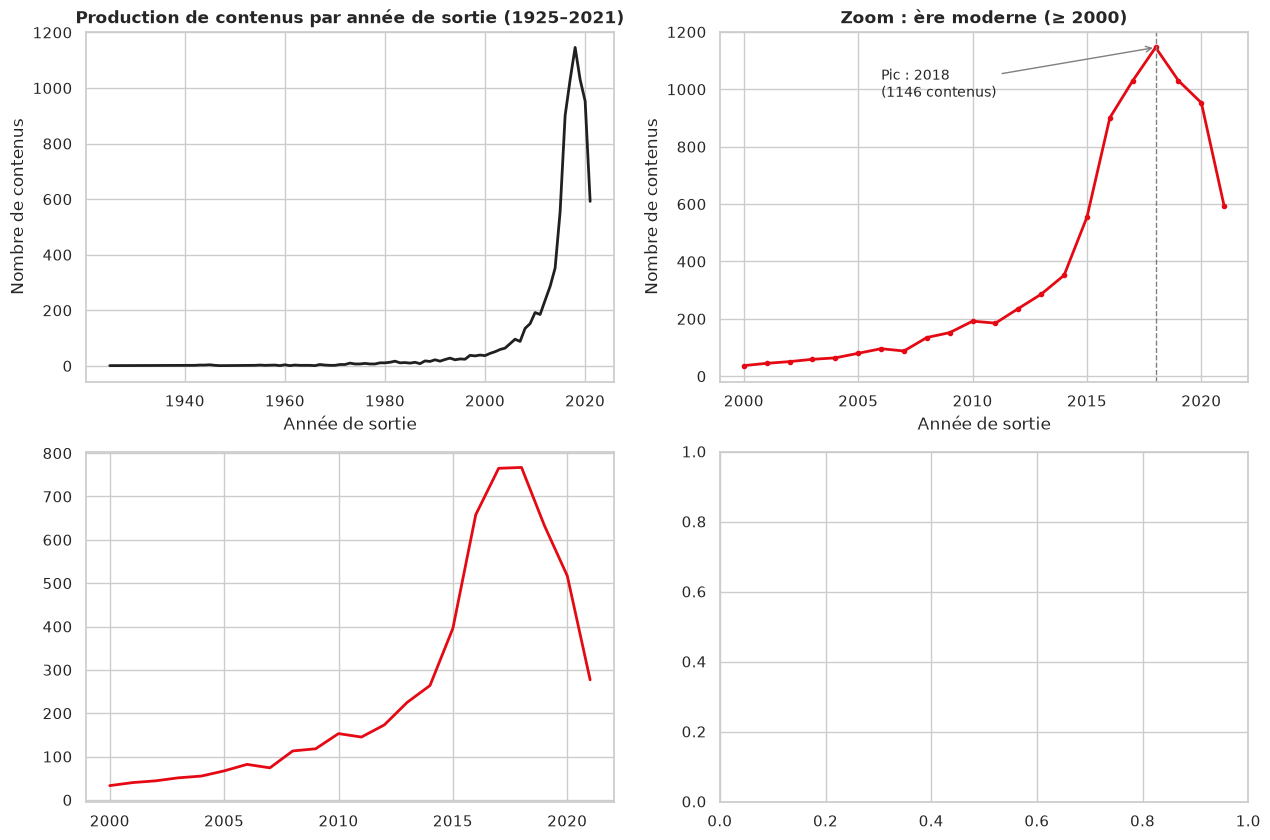

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.set_theme(style='whitegrid')

# --- 1. Vue historique complète ---
axes[0, 0].plot(par_annee.index, par_annee['total'], color='#221f1f', linewidth=2)
axes[0, 0].set_title('Production de contenus par année de sortie (1925–2021)',
                     fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Année de sortie')
axes[0, 0].set_ylabel('Nombre de contenus')

# --- 2. Zoom ère moderne + pic annoté ---
moderne = par_annee[par_annee.index >= 2000]
axes[0, 1].plot(moderne.index, moderne['total'], color='#E50914', linewidth=2, marker='o', markersize=3)
axes[0, 1].axvline(pic_annee, color='grey', linestyle='--', linewidth=1)
axes[0, 1].annotate(f'Pic : {pic_annee}\n({pic_valeur} contenus)',
                    xy=(pic_annee, pic_valeur), xytext=(pic_annee-12, pic_valeur*0.85),
                    arrowprops=dict(arrowstyle='->', color='grey'), fontsize=10)
axes[0, 1].set_title('Zoom : ère moderne (≥ 2000)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Année de sortie')
axes[0, 1].set_ylabel('Nombre de contenus')

# --- 3. Films vs séries (ère moderne) ---
axes[1, 0].plot(moderne.index, moderne['Movie'],   color='#E50914', linewidth=2, label='Films')
axes[1, 0].plot(moderne.index, moderne['TV Show'], color='#221f1f', linewidth=2, label='Séries')
axes[1, 0].set_title('Films vs Séries : deux dynamiques distinctes', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Année de sortie')
axes[1, 0].set_ylabel('Nombre de contenus')
axes[1, 0].legend()

# --- 4. Taux de croissance annuel (ère moderne) ---
axes[1, 1].bar(moderne.index, moderne['croissance_%'],
color=np.where(moderne['croissance_%'] >= 0, '#2ca02c', '#d62728'))
axes[1, 1].axhline(0, color='black', linewidth=0.8)
axes[1, 1].set_title('Taux de croissance annuel (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Année de sortie')

plt.tight_layout()
plt.show()

## Étape 5 — Interprétation des enseignements métier

In [8]:
moy_2018_2021 = par_annee.loc[2018:2021, 'total'].mean()
moy_2010_2014 = par_annee.loc[2010:2014, 'total'].mean()

print("=" * 65)
print("INTERPRÉTATION MÉTIER — Tendances de production")
print("=" * 65)
print(f"• Avant 2000, la production catalogue était marginale (< 50 titres/an).")
print(f"• L'explosion intervient dans les années 2010, avec un pic en {pic_annee}.")
print(f"• La production moyenne est passée de ~{moy_2010_2014:.0f} titres/an (2010–2014)")
print(f"  à ~{moy_2018_2021:.0f} titres/an (2018–2021) : croissance spectaculaire.")
print(f"• Le léger repli après {pic_annee} s'explique très vraisemblablement par la")
print("  pandémie de COVID-19 (2020-2021), qui a ralenti les tournages worldwide.")
print("• Les séries croissent plus vite que les films dans les années récentes :")
print("  cohérent avec la stratégie de fidélisation par les contenus originaux sériés.")
print("=" * 65)

INTERPRÉTATION MÉTIER — Tendances de production
• Avant 2000, la production catalogue était marginale (< 50 titres/an).
• L'explosion intervient dans les années 2010, avec un pic en 2018.
• La production moyenne est passée de ~250 titres/an (2010–2014)
  à ~930 titres/an (2018–2021) : croissance spectaculaire.
• Le léger repli après 2018 s'explique très vraisemblablement par la
  pandémie de COVID-19 (2020-2021), qui a ralenti les tournages worldwide.
• Les séries croissent plus vite que les films dans les années récentes :
  cohérent avec la stratégie de fidélisation par les contenus originaux sériés.


## Conclusion de la tâche 4

✔ Contenu organisé par `release_year`, contrôle qualité effectué
✔ Sorties annuelles calculées (total + films + séries)
✔ Tendances objectivées : taux de croissance annuel, pic repéré automatiquement
✔ 4 visualisations : historique complet, zoom moderne, films vs séries, croissance
✔ Interprétation métier rédigée (croissance 2010s, pic, effet COVID, stratégie séries)
